In [1]:
# standard imports
import numpy as np
import matplotlib.pyplot as plt

import xarray as xr

# import to load ARGO float data
from argopy import DataFetcher as ArgoDataFetcher

from dask.diagnostics import ProgressBar

import time

In [2]:
### Import Sea Surface Temperature (SST) data from NOAA

# # Define the OPeNDAP URL for the NOAA OISST dataset
# sst_url = "https://coastwatch.pfeg.noaa.gov/erddap/griddap/ncdcOisst21Agg_LonPM180"

# # Open the dataset with xarray
# ds_sst = xr.open_dataset(sst_url, chunks='auto')

# # Subset the data to specific region and time of interest, download subset to memory
# # This is Gulf Stream region in Jan 2023
# subset_sst = ds_sst.sel(time=slice('2023-01-01', '2023-01-31'), latitude=slice(25.0, 45.0), longitude=slice(-80.0, -50.0))

# # Plot a quick check with subsampled resolution to save time
# plt.clf()
# subset_sst.sst.isel(time=0).plot(cmap='coolwarm')
# plt.show()

# Define the OPeNDAP URL for the NOAA OISST dataset
sst_url = "https://coastwatch.pfeg.noaa.gov/erddap/griddap/ncdcOisst21Agg_LonPM180"

# Setup retry parameters
max_attempts = 3
delay_seconds = 10
ds_sst = None

# Open the dataset with xarray using a retry loop
for attempt in range(max_attempts):
    try:
        print(f"Attempt {attempt + 1} to connect to NOAA ERDDAP...")
        ds_sst = xr.open_dataset(sst_url, chunks='auto')
        print("Connection successful!")
        break
    except OSError as e:
        print(f"Connection failed: {e}")
        if attempt < max_attempts - 1:
            print(f"Retrying in {delay_seconds} seconds...")
            time.sleep(delay_seconds)
        else:
            print("All attempts failed")
            raise  # Re-raise the exception to stop execution

# Subset the data to specific region and time of interest, download subset to memory
# This is Gulf Stream region in Jan 2023
if ds_sst is not None:
    subset_sst = ds_sst.sel(time=slice('2023-01-01', '2023-01-31'), latitude=slice(25.0, 45.0), longitude=slice(-80.0, -50.0))

Attempt 1 to connect to NOAA ERDDAP...
Connection successful!


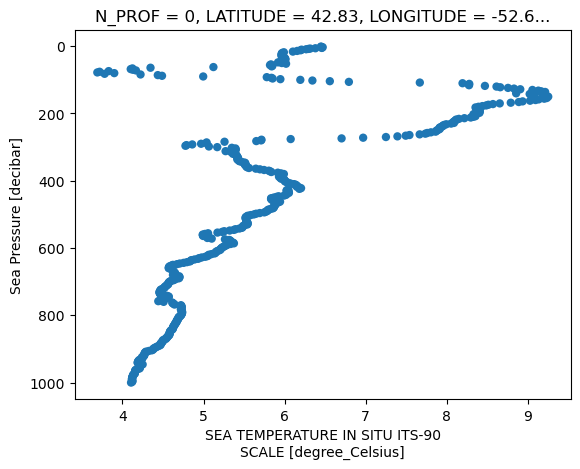

In [3]:
### Import ARGO Float data

# Spatial-temporal bounds format: [lon_min, lon_max, lat_min, lat_max, depth_min, depth_max, date_start, date_end]
argo_fetcher = ArgoDataFetcher().region([-80, -50, 25, 45, 0, 1000, '2023-01-01', '2023-01-31'])

# Fetch the data and convert to an xarray dataset
ds_argo = argo_fetcher.to_xarray()

# Argo data is initially loaded as a 1D list. Convert to standard depth-profile grid for easier analysis
ds_argo_profiles = ds_argo.argo.point2profile()

# Plot a quick temperature-depth profile for the first float
ds_argo_profiles.isel(N_PROF=0).plot.scatter(x="TEMP", y="PRES", yincrease=False, edgecolors='none')

In [4]:
# Calculate the spatial and temporal bounding box of Argo profiles
min_lon, max_lon = ds_argo_profiles['LONGITUDE'].min().values, ds_argo_profiles['LONGITUDE'].max().values
min_lat, max_lat = ds_argo_profiles['LATITUDE'].min().values, ds_argo_profiles['LATITUDE'].max().values
min_time, max_time = ds_argo_profiles['TIME'].min().values, ds_argo_profiles['TIME'].max().values

# Slice the spatial bounding box, then subsample by taking every 10th pixel
regional_sst = ds_sst.sel(time=slice(min_time, max_time), latitude=slice(min_lat, max_lat), longitude=slice(min_lon, max_lon)).isel(
    latitude=slice(None, None, 10), longitude=slice(None, None, 10))

In [5]:
# Download regional block into local memory
from dask.diagnostics import ProgressBar

with ProgressBar():
    regional_sst_loaded = regional_sst.compute()


[########################################] | 100% Completed | 10.12 s


In [6]:
# get SST data from the ARGO locations
colocated_sst = regional_sst_loaded.sst.sel(time=ds_argo_profiles['TIME'], latitude=ds_argo_profiles['LATITUDE'],
                                                     longitude=ds_argo_profiles['LONGITUDE'], method='nearest')

# Add colocated SST back into Argo dataset as a new variable
ds_argo_profiles['matched_sst'] = colocated_sst

# Convert the matched Argo/SST data into a pandas dataframe (GS_0123 means gulf stream january 2023)
df_GS_0123 = ds_argo_profiles.to_dataframe()

df_GS_0123.head()

CYCLE_NUMBER DATA_MODE DIRECTION  PLATFORM_NUMBER  \
N_PROF N_LEVELS zlev                                                      
0      0        0.0            220         D         A          4903258   
       1        0.0            220         D         A          4903258   
       2        0.0            220         D         A          4903258   
       3        0.0            220         D         A          4903258   
       4        0.0            220         D         A          4903258   

                      POSITION_QC  PRES  PRES_ERROR  PRES_QC       PSAL  \
N_PROF N_LEVELS zlev                                                      
0      0        0.0             1  1.08         2.4        1  32.740398   
       1        0.0             1  2.04         2.4        1  32.741100   
       2        0.0             1  2.96         2.4        1  32.743099   
       3        0.0             1  3.96         2.4        1  32.745201   
       4        0.0             1  5.04         2.4        1  32.746700   

                      PSAL_ERROR  ...  TEMP_ERROR  TEMP_QC  TIME_QC  LATITUDE  \
N_PROF N_LEVELS zlev              ...                                           
0      0        0.0         0.01  ...       0.002        1        1  42.82596   
       1        0.0         0.01  ...       0.002        1        1  42.82596   
       2        0.0         0.01  ...       0.002        1        1  42.82596   
       3        0.0         0.01  ...       0.002        1        1  42.82596   
       4        0.0         0.01  ...       0.002        1        1  42.82596   

                      LONGITUDE                TIME                time  \
N_PROF N_LEVELS zlev                                                      
0      0        0.0   -52.65462 2023-01-01 02:16:37 2023-01-01 12:00:00   
       1        0.0   -52.65462 2023-01-01 02:16:37 2023-01-01 12:00:00   
       2        0.0   -52.65462 2023-01-01 02:16:37 2023-01-01 12:00:00   
       3        0.0   -52.65462 2023-01-01 02:16:37 2023-01-01 12:00:00   
       4        0.0   -52.65462 2023-01-01 02:16:37 2023-01-01 12:00:00   

                     latitude longitude  matched_sst  
N_PROF N_LEVELS zlev                                  
0      0        0.0    42.625   -52.125         12.6  
       1        0.0    42.625   -52.125         12.6  
       2        0.0    42.625   -52.125         12.6  
       3        0.0    42.625   -52.125         12.6  
       4        0.0    42.625   -52.125         12.6  

[5 rows x 22 columns]

In [7]:
df_GS_0123.info()

<class 'pandas.DataFrame'>
MultiIndex: 150070 entries, (np.int64(0), np.int64(0), np.float32(0.0)) to (np.int64(214), np.int64(697), np.float32(0.0))
Data columns (total 22 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   CYCLE_NUMBER     150070 non-null  int64         
 1   DATA_MODE        150070 non-null  str           
 2   DIRECTION        150070 non-null  str           
 3   PLATFORM_NUMBER  150070 non-null  int64         
 4   POSITION_QC      150070 non-null  int64         
 5   PRES             97145 non-null   float32       
 6   PRES_ERROR       113774 non-null  float32       
 7   PRES_QC          150070 non-null  int64         
 8   PSAL             97145 non-null   float32       
 9   PSAL_ERROR       70420 non-null   float32       
 10  PSAL_QC          150070 non-null  int64         
 11  TEMP             97145 non-null   float32       
 12  TEMP_ERROR       113774 non-null  float32       
 13  TE

- There a null values that we will have to deal with in the columns: PRES, PRES_ERROR, PSAL, PSAL_ERROR, TEMP, TEMP_ERROR
- There are a few non-numeric columns: DATA_MODE and DIRECTION are strings, and TIME and tim are in datetime64